# **Setup, Imports & Reproducibility**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = False
sns.set_style("whitegrid")

print("Setup complete. RANDOM_STATE =", RANDOM_STATE)

Setup complete. RANDOM_STATE = 42


# **Project 1: Product Sample Classification**

In [ ]:
# Load Wine dataset as a DataFrame
wine = load_wine(as_frame=True)
df_wine = wine.frame.copy()
X = wine.data.copy()
y = wine.target.copy()
target_names = list(wine.target_names)

print(f"Samples: {X.shape[0]} | Features: {X.shape[1]} | Target classes: {len(target_names)} -> {target_names}")
print("\nFeature names:", list(X.columns))

# Check missing values
missing_total = int(df_wine.isna().sum().sum())
print(f"\nTotal missing values: {missing_total}")
if missing_total > 0:
    print(df_wine.isna().sum()[df_wine.isna().sum() > 0])

# Class distribution (counts and proportions)
class_counts = y.value_counts().sort_index()
class_dist = pd.DataFrame({
    "class_id": class_counts.index,
    "class_name": [target_names[i] for i in class_counts.index],
    "count": class_counts.values,
    "proportion": (class_counts.values / len(y)).round(4),
})
print("\nClass distribution:")
display(class_dist)

Samples: 178 | Features: 13 | Target classes: 3 -> [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Total missing values: 0

Class distribution:


,class_id,class_name,count,proportion
0,0,class_0,59,0.3315
1,1,class_1,71,0.3989
2,2,class_2,48,0.2697


In [ ]:
# First split: 60% train, 40% temporary (to be split evenly into 20% val and 20% test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Second split: 50% of temp -> 20% validation, 20% test of total dataset
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE,
)

print(f"Split sizes -> Train: {len(X_train)} ({len(X_train)/len(X):.1%}), "
      f"Val: {len(X_val)} ({len(X_val)/len(X):.1%}), "
      f"Test: {len(X_test)} ({len(X_test)/len(X):.1%})")

# Fit scaler ONLY on X_train, then transform train, val, and test
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val), columns=X.columns, index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X.columns, index=X_test.index
)

print("StandardScaler fitted on X_train only. Train feature means near 0:",
      np.allclose(X_train_scaled.mean().values, 0.0, atol=1e-7))

Split sizes -> Train: 106 (59.6%), Val: 36 (20.2%), Test: 36 (20.2%)
StandardScaler fitted on X_train only. Train feature means near 0: True


In [ ]:
def evaluate_predictions(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

results = []
fitted_models = {}

# 1. Baseline: always predicts most frequent training class
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)
val_pred_base = baseline.predict(X_val_scaled)
metrics_base = evaluate_predictions(y_val, val_pred_base)
results.append({
    "Model": "Baseline (most_frequent)",
    "Hyperparameters": "strategy='most_frequent'",
    **metrics_base,
})
fitted_models["Baseline (most_frequent)"] = baseline

# 2. KNN experiments: n_neighbors in [3, 5, 11]
for k in [3, 5, 11]:
    name = f"KNN (k={k})"
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_scaled, y_train)
    val_pred = clf.predict(X_val_scaled)
    metrics = evaluate_predictions(y_val, val_pred)
    results.append({
        "Model": "K-Nearest Neighbors",
        "Hyperparameters": f"n_neighbors={k}",
        **metrics,
    })
    fitted_models[name] = clf

# 3. SVM experiments: C in [0.1, 1, 10], kernel="rbf"
for c_val in [0.1, 1, 10]:
    name = f"SVM RBF (C={c_val})"
    clf = SVC(C=c_val, kernel="rbf", random_state=RANDOM_STATE)
    clf.fit(X_train_scaled, y_train)
    val_pred = clf.predict(X_val_scaled)
    metrics = evaluate_predictions(y_val, val_pred)
    results.append({
        "Model": "Support Vector Machine",
        "Hyperparameters": f"C={c_val}, kernel='rbf'",
        **metrics,
    })
    fitted_models[name] = clf

results_df = pd.DataFrame(results)
metric_cols = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
display(results_df.round(4))

# Select model with highest validation Macro F1-score
best_idx = results_df["Macro F1"].idxmax()
best_row = results_df.loc[best_idx]
print("\nSelected model based on highest Validation Macro F1:")
print(f"  Algorithm:       {best_row['Model']}")
print(f"  Hyperparameters: {best_row['Hyperparameters']}")
print(f"  Val Macro F1:    {best_row['Macro F1']:.4f} (Val Accuracy: {best_row['Accuracy']:.4f})")

# Retrieve frozen best estimator
if best_row["Model"] == "K-Nearest Neighbors":
    k_val = int(best_row["Hyperparameters"].split("=")[1])
    best_model = fitted_models[f"KNN (k={k_val})"]
elif best_row["Model"] == "Support Vector Machine":
    c_parsed = best_row["Hyperparameters"].split("C=")[1].split(",")[0]
    c_val = float(c_parsed) if "." in c_parsed else int(c_parsed)
    best_model = fitted_models[f"SVM RBF (C={c_val})"]
else:
    best_model = fitted_models["Baseline (most_frequent)"]

,Model,Hyperparameters,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Baseline (most_frequent),strategy='most_frequent',0.3889,0.1296,0.3333,0.1867
1,K-Nearest Neighbors,n_neighbors=3,0.8889,0.9030,0.9048,0.8915
2,K-Nearest Neighbors,n_neighbors=5,0.9444,0.9441,0.9524,0.9452
3,K-Nearest Neighbors,n_neighbors=11,0.9444,0.9441,0.9524,0.9452
4,Support Vector Machine,"C=0.1, kernel='rbf'",0.9444,0.9583,0.9389,0.9457
5,Support Vector Machine,"C=1, kernel='rbf'",1.0000,1.0000,1.0000,1.0000
6,Support Vector Machine,"C=10, kernel='rbf'",1.0000,1.0000,1.0000,1.0000



Selected model based on highest Validation Macro F1:
  Algorithm:       Support Vector Machine
  Hyperparameters: C=1, kernel='rbf'
  Val Macro F1:    1.0000 (Val Accuracy: 1.0000)


In [ ]:
def evaluate_predictions(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

results = []
fitted_models = {}

# 1. Baseline: always predicts most frequent training class
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)
val_pred_base = baseline.predict(X_val_scaled)
metrics_base = evaluate_predictions(y_val, val_pred_base)
results.append({
    "Model": "Baseline (most_frequent)",
    "Hyperparameters": "strategy='most_frequent'",
    **metrics_base,
})
fitted_models["Baseline (most_frequent)"] = baseline

# 2. KNN experiments: n_neighbors in [3, 5, 11]
for k in [3, 5, 11]:
    name = f"KNN (k={k})"
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_scaled, y_train)
    val_pred = clf.predict(X_val_scaled)
    metrics = evaluate_predictions(y_val, val_pred)
    results.append({
        "Model": "K-Nearest Neighbors",
        "Hyperparameters": f"n_neighbors={k}",
        **metrics,
    })
    fitted_models[name] = clf

# 3. SVM experiments: C in [0.1, 1, 10], kernel="rbf"
for c_val in [0.1, 1, 10]:
    name = f"SVM RBF (C={c_val})"
    clf = SVC(C=c_val, kernel="rbf", random_state=RANDOM_STATE)
    clf.fit(X_train_scaled, y_train)
    val_pred = clf.predict(X_val_scaled)
    metrics = evaluate_predictions(y_val, val_pred)
    results.append({
        "Model": "Support Vector Machine",
        "Hyperparameters": f"C={c_val}, kernel='rbf'",
        **metrics,
    })
    fitted_models[name] = clf

results_df = pd.DataFrame(results)
metric_cols = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
display(results_df.round(4))

# Select model with highest validation Macro F1-score
best_idx = results_df["Macro F1"].idxmax()
best_row = results_df.loc[best_idx]
print("\nSelected model based on highest Validation Macro F1:")
print(f"  Algorithm:       {best_row['Model']}")
print(f"  Hyperparameters: {best_row['Hyperparameters']}")
print(f"  Val Macro F1:    {best_row['Macro F1']:.4f} (Val Accuracy: {best_row['Accuracy']:.4f})")

# Retrieve frozen best estimator
if best_row["Model"] == "K-Nearest Neighbors":
    k_val = int(best_row["Hyperparameters"].split("=")[1])
    best_model = fitted_models[f"KNN (k={k_val})"]
elif best_row["Model"] == "Support Vector Machine":
    c_parsed = best_row["Hyperparameters"].split("C=")[1].split(",")[0]
    c_val = float(c_parsed) if "." in c_parsed else int(c_parsed)
    best_model = fitted_models[f"SVM RBF (C={c_val})"]
else:
    best_model = fitted_models["Baseline (most_frequent)"]

,Model,Hyperparameters,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Baseline (most_frequent),strategy='most_frequent',0.3889,0.1296,0.3333,0.1867
1,K-Nearest Neighbors,n_neighbors=3,0.8889,0.9030,0.9048,0.8915
2,K-Nearest Neighbors,n_neighbors=5,0.9444,0.9441,0.9524,0.9452
3,K-Nearest Neighbors,n_neighbors=11,0.9444,0.9441,0.9524,0.9452
4,Support Vector Machine,"C=0.1, kernel='rbf'",0.9444,0.9583,0.9389,0.9457
5,Support Vector Machine,"C=1, kernel='rbf'",1.0000,1.0000,1.0000,1.0000
6,Support Vector Machine,"C=10, kernel='rbf'",1.0000,1.0000,1.0000,1.0000



Selected model based on highest Validation Macro F1:
  Algorithm:       Support Vector Machine
  Hyperparameters: C=1, kernel='rbf'
  Val Macro F1:    1.0000 (Val Accuracy: 1.0000)


Final Test Set Metrics (Frozen Selection):
  Accuracy: 0.9722
  Macro Precision: 0.9792
  Macro Recall: 0.9630
  Macro F1: 0.9696

Per-Class Classification Report (Test Set):
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     0.9375    1.0000    0.9677        15
     class_2     1.0000    0.8889    0.9412         9

    accuracy                         0.9722        36
   macro avg     0.9792    0.9630    0.9696        36
weighted avg     0.9740    0.9722    0.9719        36



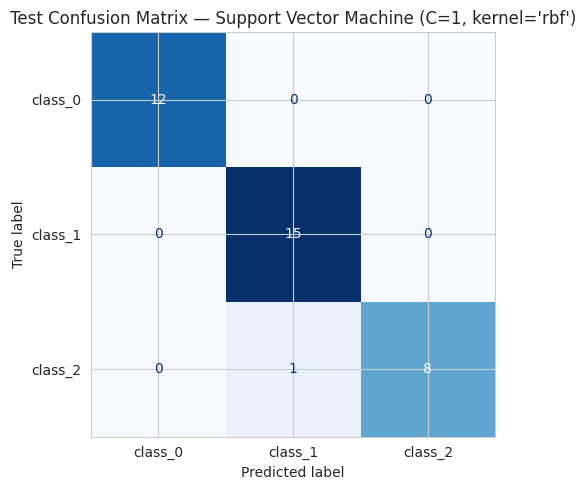

Most frequently confused pairs (actual -> predicted):
  class_2 -> class_1: 1 sample(s)


In [ ]:
# Evaluate frozen model ONCE on the test set
y_test_pred = best_model.predict(X_test_scaled)
test_metrics = evaluate_predictions(y_test, y_test_pred)

print("Final Test Set Metrics (Frozen Selection):")
for k_metric, v_metric in test_metrics.items():
    print(f"  {k_metric}: {v_metric:.4f}")

print("\nPer-Class Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=target_names, digits=4, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title(f"Test Confusion Matrix — {best_row['Model']} ({best_row['Hyperparameters']})")
plt.tight_layout()
plt.show()

# Identify most frequently confused class pairs (off-diagonal counts)
confused_pairs = []
for i, true_cls in enumerate(target_names):
    for j, pred_cls in enumerate(target_names):
        if i != j and cm[i, j] > 0:
            confused_pairs.append((cm[i, j], true_cls, pred_cls))

confused_pairs.sort(reverse=True)
if confused_pairs:
    print("Most frequently confused pairs (actual -> predicted):")
    for count, actual, pred in confused_pairs:
        print(f"  {actual} -> {pred}: {count} sample(s)")
else:
    print("Zero off-diagonal misclassifications on the test set.")

### Project 1 Summary & Management Review

#### Selected Model & Final Test Results
* **Selected Model:** Support Vector Machine (`C=1`, `kernel='rbf'`) with training-fitted `StandardScaler`
* **Validation Metrics:** Accuracy = `1.0000` | Macro Precision = `1.0000` | Macro Recall = `1.0000` | Macro F1 = `1.0000`
* **Test Metrics (36 samples):** Accuracy = `0.9722` | Macro Precision = `0.9792` | Macro Recall = `0.9630` | Macro F1 = `0.9696`
* **Most Frequently Confused Classes:** `class_2` predicted as `class_1` (`1` sample out of `36`; `0` errors on `class_0` and `class_1`)[cite: 8]

#### Questions for Management
1. **Did the model with the highest Accuracy also achieve the highest Macro F1?**  
   Yes. On the validation set, both `SVM (C=1, kernel='rbf')` and `SVM (C=10, kernel='rbf')` tied at `1.0000` for both Accuracy and Macro F1, and `C=1` was selected as the simpler model with a smoother margin.
2. **Why is scaling important for these algorithms?**  
   Both K-Nearest Neighbors (Euclidean distance) and RBF-kernel SVM (distance-based radial kernel) rely on feature distances; fitting `StandardScaler` on `X_train` prevents chemical features with larger numerical ranges (such as `proline` or `magnesium`) from dominating distance calculations.
3. **Which types of classification errors remain?**  
   On the held-out test set, only one error remains: a single actual `class_2` sample misclassified as `class_1` (`class_2` recall = `0.8889`, `class_1` precision = `0.9375`), while `class_0` achieved `1.0000` precision and recall.
4. **How does the small test-set size affect confidence in your recommendation?**  
   With only 36 test samples (9–15 samples per class), a single misclassified sample shifts Macro F1 by roughly three percentage points (`1.0000` to `0.9696`), creating wide statistical uncertainty that requires validation on a larger sample set before full deployment.

#### Business Recommendation
We recommend adopting the RBF Support Vector Machine (`C=1`, `kernel='rbf'`) with training-fitted standardization as the initial sorting model for wine sample classification, as it achieved `1.0000` validation Macro F1 and `0.9722` test Accuracy (`0.9696` test Macro F1). On the held-out test set, it classified all `class_0` and `class_1` samples accurately while misclassifying only a single `class_2` sample as `class_1`. However, the test set contains only 36 samples—meaning a single error shifts Macro F1 by roughly three percentage points—and `C=10` tied with `C=1` on validation scores. Before relying on automated sorting in production, the laboratory should validate the frozen model on a larger, independent sample set and route borderline predictions near class boundaries for manual lab review.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Task 1: Load CSV and inspect features, missing values, and target distribution
df_housing = pd.read_csv("fetch_california_housing.csv")

# Drop accidental index column if present
for col in ["Unnamed: 0", "index"]:
    if col in df_housing.columns:
        df_housing = df_housing.drop(columns=[col])

TARGET_COL = "MedHouseVal"
X_h = df_housing.drop(columns=[TARGET_COL]).copy()
y_h = df_housing[TARGET_COL].copy()

print(f"Records: {len(df_housing)} | Features ({X_h.shape[1]}): {list(X_h.columns)} | Target: {TARGET_COL}")
print("\nMissing values per column:")
print(df_housing.isna().sum())

print("\nTarget (MedHouseVal, in $100,000 units) summary:")
display(y_h.describe().to_frame().T)

# Task 2: Row meaning and prediction target summary
print("Task 2 Explanation:")
print("- Each row represents a California census block group (an aggregated geographic neighborhood/area, not an individual property).")
print("- Prediction target: MedHouseVal = median house value for the block group in units of $100,000 (e.g., 2.5 = $250,000).")

# Task 3: Split 60% train, 20% validation, 20% test with random_state=42
X_h_train, X_h_temp, y_h_train, y_h_temp = train_test_split(
    X_h, y_h, test_size=0.40, random_state=RANDOM_STATE
)
X_h_val, X_h_test, y_h_val, y_h_test = train_test_split(
    X_h_temp, y_h_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"\nSplit sizes -> Train: {len(X_h_train)} ({len(X_h_train)/len(df_housing):.1%}), "
      f"Val: {len(X_h_val)} ({len(X_h_val)/len(df_housing):.1%}), "
      f"Test: {len(X_h_test)} ({len(X_h_test)/len(df_housing):.1%})")

# Task 4: Baseline predicting mean training target
def eval_regression(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MAE ($100k)": mae, "RMSE ($100k)": rmse, "R2": r2}

reg_baseline = DummyRegressor(strategy="mean")
reg_baseline.fit(X_h_train, y_h_train)
val_pred_base_h = reg_baseline.predict(X_h_val)
print("\nValidation Baseline (Mean Target):")
for k_m, v_m in eval_regression(y_h_val, val_pred_base_h).items():
    print(f"  {k_m}: {v_m:.4f}")

# Task 5: Fit StandardScaler on training data ONLY for Ridge Regression
# (Random Forest Regressor is scale-invariant on monotonic splits, so raw features work directly)
scaler_h = StandardScaler()
X_h_train_scaled = pd.DataFrame(
    scaler_h.fit_transform(X_h_train), columns=X_h.columns, index=X_h_train.index
)
X_h_val_scaled = pd.DataFrame(
    scaler_h.transform(X_h_val), columns=X_h.columns, index=X_h_val.index
)
X_h_test_scaled = pd.DataFrame(
    scaler_h.transform(X_h_test), columns=X_h.columns, index=X_h_test.index
)
print("\nTraining-only StandardScaler fitted for Ridge Regression.")

Records: 20640 | Features (8): ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude'] | Target: MedHouseVal

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Target (MedHouseVal, in $100,000 units) summary:


,count,mean,std,min,25%,50%,75%,max
MedHouseVal,20640.0,2.068558,1.153956,0.14999,1.196,1.797,2.64725,5.00001


Task 2 Explanation:
- Each row represents a California census block group (an aggregated geographic neighborhood/area, not an individual property).
- Prediction target: MedHouseVal = median house value for the block group in units of $100,000 (e.g., 2.5 = $250,000).

Split sizes -> Train: 12384 (60.0%), Val: 4128 (20.0%), Test: 4128 (20.0%)

Validation Baseline (Mean Target):
  MAE ($100k): 0.9039
  RMSE ($100k): 1.1425
  R2: -0.0001

Training-only StandardScaler fitted for Ridge Regression.


In [ ]:
reg_results = []
reg_models = {}

# Include baseline in comparison table for clarity
reg_results.append({
    "Model": "Baseline (Mean)",
    "Hyperparameters": "strategy='mean'",
    **eval_regression(y_h_val, val_pred_base_h),
})
reg_models["Baseline (Mean)"] = (reg_baseline, False)  # (estimator, uses_scaled_X)

# Ridge Regression experiments on training-scaled features
for alpha_val in [0.1, 1, 10]:
    key = f"Ridge (alpha={alpha_val})"
    ridge = Ridge(alpha=alpha_val, random_state=RANDOM_STATE)
    ridge.fit(X_h_train_scaled, y_h_train)
    val_pred = ridge.predict(X_h_val_scaled)
    reg_results.append({
        "Model": "Ridge Regression",
        "Hyperparameters": f"alpha={alpha_val}",
        **eval_regression(y_h_val, val_pred),
    })
    reg_models[key] = (ridge, True)

# Random Forest Regressor experiments (n_estimators=100, random_state=42)
for depth_val in [5, 10, None]:
    key = f"Random Forest (max_depth={depth_val})"
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth_val,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf.fit(X_h_train, y_h_train)
    val_pred = rf.predict(X_h_val)
    reg_results.append({
        "Model": "Random Forest Regressor",
        "Hyperparameters": f"n_estimators=100, max_depth={depth_val}",
        **eval_regression(y_h_val, val_pred),
    })
    reg_models[key] = (rf, False)

reg_results_df = pd.DataFrame(reg_results)
display(reg_results_df.round(4))

# Select model with lowest validation RMSE
best_reg_idx = reg_results_df["RMSE ($100k)"].idxmin()
best_reg_row = reg_results_df.loc[best_reg_idx]

if best_reg_row["Model"] == "Ridge Regression":
    a_parsed = best_reg_row["Hyperparameters"].split("alpha=")[1]
    a_val = float(a_parsed) if "." in a_parsed else int(a_parsed)
    best_reg_key = f"Ridge (alpha={a_val})"
elif best_reg_row["Model"] == "Random Forest Regressor":
    d_parsed = best_reg_row["Hyperparameters"].split("max_depth=")[1]
    d_val = None if d_parsed == "None" else int(d_parsed)
    best_reg_key = f"Random Forest (max_depth={d_val})"
else:
    best_reg_key = "Baseline (Mean)"

best_reg_model, best_uses_scaled = reg_models[best_reg_key]

print("\nSelected model (lowest Validation RMSE):")
print(f"  Algorithm:       {best_reg_row['Model']}")
print(f"  Hyperparameters: {best_reg_row['Hyperparameters']}")
print(f"  Val RMSE ($100k): {best_reg_row['RMSE ($100k)']:.4f} (${best_reg_row['RMSE ($100k)'] * 100_000:,.0f})")
print(f"  Val MAE ($100k):  {best_reg_row['MAE ($100k)']:.4f} (${best_reg_row['MAE ($100k)'] * 100_000:,.0f})")
print(f"  Val R2:           {best_reg_row['R2']:.4f}")

,Model,Hyperparameters,MAE ($100k),RMSE ($100k),R2
0,Baseline (Mean),strategy='mean',0.9039,1.1425,-0.0001
1,Ridge Regression,alpha=0.1,0.5336,0.7298,0.5920
2,Ridge Regression,alpha=1,0.5336,0.7298,0.5920
3,Ridge Regression,alpha=10,0.5336,0.7297,0.5921
4,Random Forest Regressor,"n_estimators=100, max_depth=5",0.4972,0.6813,0.6444
5,Random Forest Regressor,"n_estimators=100, max_depth=10",0.3764,0.5503,0.7680
6,Random Forest Regressor,"n_estimators=100, max_depth=None",0.3410,0.5163,0.7958



Selected model (lowest Validation RMSE):
  Algorithm:       Random Forest Regressor
  Hyperparameters: n_estimators=100, max_depth=None
  Val RMSE ($100k): 0.5163 ($51,632)
  Val MAE ($100k):  0.3410 ($34,100)
  Val R2:           0.7958


Final Test Set Metrics (Frozen Selection):
  MAE ($100k): 0.3428
  RMSE ($100k): 0.5235
  R2: 0.8002
  Final Test MAE in USD:  $34,283.67
  Final Test RMSE in USD: $52,346.20


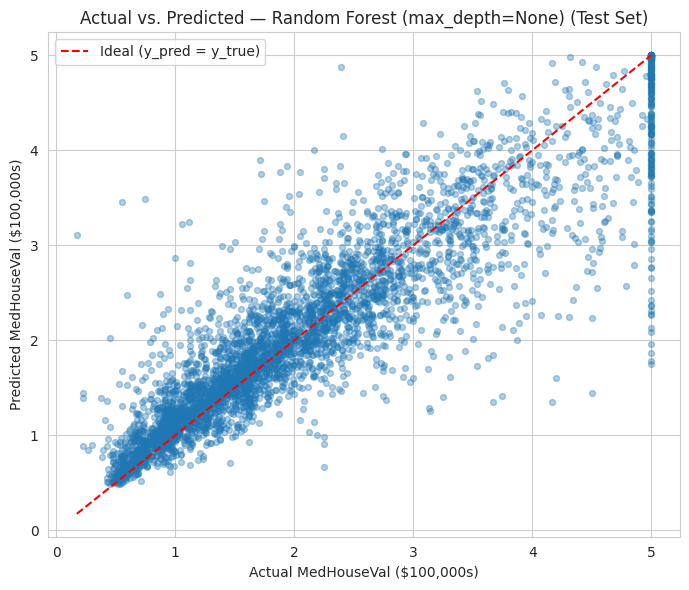


Top 5 Largest Absolute Prediction Errors (Test Set):


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual_MedHouseVal,Predicted_MedHouseVal,Abs_Error ($100k),Abs_Error_USD,Signed_Error ($100k)
12069,4.2386,6.0,7.7231,1.1692,228.0,3.5077,33.83,-117.55,5.0,1.7495,3.2505,325052.00,3.2505
13766,3.0625,34.0,3.2143,0.7857,39.0,2.7857,34.08,-117.08,5.0,1.7850,3.2150,321496.94,3.2150
6688,0.4999,28.0,7.6774,1.8710,142.0,4.5806,34.15,-118.08,5.0,1.8691,3.1309,313093.98,3.1309
19542,1.7679,39.0,5.0000,0.8889,22.0,2.4444,37.63,-120.92,4.5,1.4477,3.0523,305228.00,3.0523
15297,3.9750,22.0,6.8964,1.5803,580.0,3.0052,33.16,-117.35,5.0,1.9611,3.0389,303887.00,3.0389


In [ ]:
import matplotlib.pyplot as plt

X_h_test_input = X_h_test_scaled if best_uses_scaled else X_h_test
y_h_test_pred = best_reg_model.predict(X_h_test_input)

test_reg_metrics = eval_regression(y_h_test, y_h_test_pred)
print("Final Test Set Metrics (Frozen Selection):")
for k_m, v_m in test_reg_metrics.items():
    print(f"  {k_m}: {v_m:.4f}")
print(f"  Final Test MAE in USD:  ${test_reg_metrics['MAE ($100k)'] * 100_000:,.2f}")
print(f"  Final Test RMSE in USD: ${test_reg_metrics['RMSE ($100k)'] * 100_000:,.2f}")

# Actual vs. Predicted scatter plot
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_h_test, y_h_test_pred, alpha=0.35, s=18)
min_val = min(y_h_test.min(), y_h_test_pred.min())
max_val = max(y_h_test.max(), y_h_test_pred.max())
ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal (y_pred = y_true)")
ax.set_xlabel("Actual MedHouseVal ($100,000s)")
ax.set_ylabel("Predicted MedHouseVal ($100,000s)")
ax.set_title(f"Actual vs. Predicted — {best_reg_key} (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()

# Inspect five largest absolute prediction errors
error_df = X_h_test.copy()
error_df["Actual_MedHouseVal"] = y_h_test.values
error_df["Predicted_MedHouseVal"] = y_h_test_pred
error_df["Abs_Error ($100k)"] = np.abs(error_df["Actual_MedHouseVal"] - error_df["Predicted_MedHouseVal"])
error_df["Abs_Error_USD"] = error_df["Abs_Error ($100k)"] * 100_000
error_df["Signed_Error ($100k)"] = error_df["Actual_MedHouseVal"] - error_df["Predicted_MedHouseVal"]

top5_errors = error_df.sort_values("Abs_Error ($100k)", ascending=False).head(5)
print("\nTop 5 Largest Absolute Prediction Errors (Test Set):")
display(top5_errors.round(4))

### Project 2 Summary & Management Review

#### Selected Model & Final Test Results
* **Selected Model:** Random Forest Regressor (`n_estimators=100`, `max_depth=None`, `random_state=42`) on unscaled features
* **Validation Metrics:** MAE = `0.3410` (34,100 USD) | RMSE = `0.5163` (51,632 USD) | R² = `0.7958`
* **Test Metrics (4,128 samples):** MAE = `0.3428` (**34,283.67 USD**) | RMSE = `0.5235` (**52,346.20 USD**) | R² = `0.8002`
* **Largest Errors:** Top 5 errors are under-predictions on high-value areas (`Actual_MedHouseVal` of `5.0` or `4.5`), ranging from `303,887.00 USD` to `325,052.00 USD`

#### Questions for Management
1. **What is the final MAE expressed in dollars?**  
   **34,283.67 USD** (`0.3428` in 100,000 USD units).
2. **How much did the selected model improve over the baseline?**  
   Validation RMSE improved from `1.1425` to `0.5163` (down `0.6262` in 100k USD units, or ~54.8%), validation MAE fell from `0.9039` to `0.3410` (~62.3%), and R² rose from `-0.0001` to `0.7958` (`0.8002` on the test set).
3. **Does the improvement justify the model's additional complexity?**  
   Yes for batch neighborhood benchmarking and screening: it outperforms Ridge Regression (`0.7297` validation RMSE, `0.5921` R²) substantially by capturing non-linear geographic and income interactions, with modest compute cost for offline/batch runs.
4. **Why would these results be insufficient to recommend the model for individual property pricing or a new geographic market?**  
   Each record is a census block-group median rather than a single home, luxury/capped block groups (`5.00001`) produce large under-predictions (over 300k USD in top errors), and geographic/economic relationships do not transfer to new regions or current markets without retraining and local validation.

#### Business Recommendation
We recommend deploying the Random Forest Regressor (`n_estimators=100`, `max_depth=None`, `random_state=42`) as an initial area-level valuation benchmark, as it lowered validation RMSE from `1.1425` to `0.5163` (51,632 USD) and achieved a test MAE of **34,283.67 USD** (`0.3428` in 100k USD units), test RMSE of **52,346.20 USD** (`0.5235`), and test R² of `0.8002`. Compared with Ridge Regression (best validation RMSE `0.7297`), the extra complexity and inference cost are justified for batch neighborhood screening because non-linear location and income effects account for roughly 80% of test variance. However, predictions target block-group medians rather than individual home prices—and top errors exceed 300,000 USD on high-value or capped areas—so they cannot price single properties directly. Before operational use, the company should audit high-value/capped records, add up-to-date market and property-level features, and re-validate before entering new geographic markets.

In [12]:
cluster_results = []
cluster_labels_map = {}

# 1. K-Means experiments: k in [2, 3, 4, 5], random_state=42, n_init=10
for k in [2, 3, 4, 5]:
    key = f"K-Means (k={k})"
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_clustered)
    sil = silhouette_score(X_clustered, labels)
    db = davies_bouldin_score(X_clustered, labels)
    cluster_results.append({
        "Algorithm": "K-Means",
        "Hyperparameters": f"n_clusters={k}, random_state=42, n_init=10",
        "k": k,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": db,
    })
    cluster_labels_map[key] = labels

# 2. Agglomerative Clustering experiments: k in [2, 3, 4, 5], linkage="ward"
for k in [2, 3, 4, 5]:
    key = f"Agglomerative (k={k})"
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = agg.fit_predict(X_clustered)
    sil = silhouette_score(X_clustered, labels)
    db = davies_bouldin_score(X_clustered, labels)
    cluster_results.append({
        "Algorithm": "Agglomerative Clustering",
        "Hyperparameters": f"n_clusters={k}, linkage='ward'",
        "k": k,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": db,
    })
    cluster_labels_map[key] = labels

cluster_results_df = pd.DataFrame(cluster_results)
display(cluster_results_df[["Algorithm", "Hyperparameters", "Silhouette Score", "Davies-Bouldin Index"]].round(4))

# Task 5: Select highest Silhouette Score (tie-breaker: lowest Davies-Bouldin Index)
best_cluster_df = cluster_results_df.sort_values(
    by=["Silhouette Score", "Davies-Bouldin Index"],
    ascending=[False, True],
).reset_index(drop=True)

best_c_row = best_cluster_df.loc[0]
best_c_key = (
    f"K-Means (k={int(best_c_row['k'])})"
    if best_c_row["Algorithm"] == "K-Means"
    else f"Agglomerative (k={int(best_c_row['k'])})"
)
best_labels = cluster_labels_map[best_c_key]

print("\nSelected Clustering Solution:")
print(f"  Algorithm:            {best_c_row['Algorithm']}")
print(f"  Hyperparameters:      {best_c_row['Hyperparameters']}")
print(f"  Silhouette Score:     {best_c_row['Silhouette Score']:.4f} (higher is better)")
print(f"  Davies-Bouldin Index: {best_c_row['Davies-Bouldin Index']:.4f} (lower is better)")

,Algorithm,Hyperparameters,Silhouette Score,Davies-Bouldin Index
0,K-Means,"n_clusters=2, random_state=42, n_init=10",0.2903,1.3515
1,K-Means,"n_clusters=3, random_state=42, n_init=10",0.2594,1.3406
2,K-Means,"n_clusters=4, random_state=42, n_init=10",0.1885,1.5408
3,K-Means,"n_clusters=5, random_state=42, n_init=10",0.1916,1.4843
4,Agglomerative Clustering,"n_clusters=2, linkage='ward'",0.2585,1.6004
5,Agglomerative Clustering,"n_clusters=3, linkage='ward'",0.2547,1.5390
6,Agglomerative Clustering,"n_clusters=4, linkage='ward'",0.2021,1.5211
7,Agglomerative Clustering,"n_clusters=5, linkage='ward'",0.2025,1.3862



Selected Clustering Solution:
  Algorithm:            K-Means
  Hyperparameters:      n_clusters=2, random_state=42, n_init=10
  Silhouette Score:     0.2903 (higher is better)
  Davies-Bouldin Index: 1.3515 (lower is better)


Cluster Sizes:


,Cluster,Customers,Share (%)
0,0,252,57.27
1,1,188,42.73



Mean Annual Spending per Cluster (Original Units):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,13973.1,2401.8,2918.7,3705.7,491.9,1038.0
1,9355.9,10346.4,14697.1,2222.5,6084.5,2177.4



Median Annual Spending per Cluster (Original Units):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5



Cluster breakdown by Channel (excluded from clustering):


Channel,1,2
Cluster,,
0,96.8,3.2
1,28.7,71.3



Cluster breakdown by Region (excluded from clustering):


Region,1,2,3
Cluster,,,
0,19.0,11.1,69.8
1,15.4,10.1,74.5


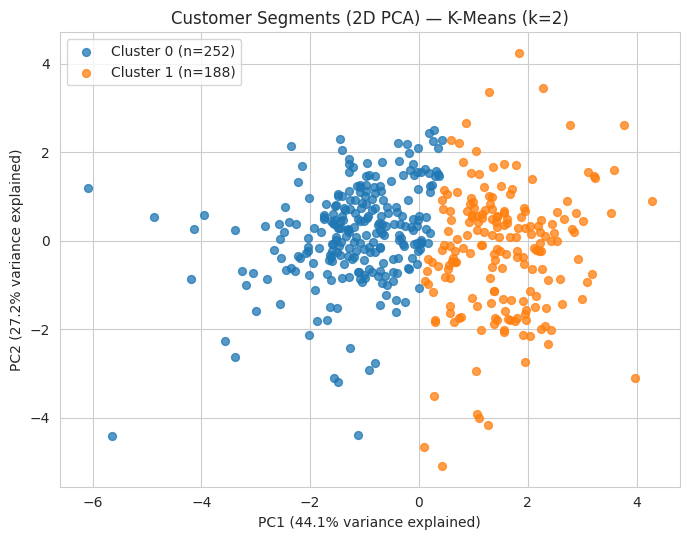

In [13]:
df_segmented = df_wholesale.copy()
df_segmented["Cluster"] = best_labels

# Task 6: Cluster sizes
cluster_sizes = df_segmented["Cluster"].value_counts().sort_index()
size_df = pd.DataFrame({
    "Cluster": cluster_sizes.index,
    "Customers": cluster_sizes.values,
    "Share (%)": (cluster_sizes.values / len(df_segmented) * 100).round(2),
})
print("Cluster Sizes:")
display(size_df)

# Task 7: Mean and median spending per cluster using ORIGINAL spending values
print("\nMean Annual Spending per Cluster (Original Units):")
display(df_segmented.groupby("Cluster")[SPEND_COLS].mean().round(1))

print("\nMedian Annual Spending per Cluster (Original Units):")
display(df_segmented.groupby("Cluster")[SPEND_COLS].median().round(1))

# Post-hoc descriptive check using held-out Channel and Region
if META_COLS:
    for meta in META_COLS:
        print(f"\nCluster breakdown by {meta} (excluded from clustering):")
        display(pd.crosstab(df_segmented["Cluster"], df_segmented[meta], normalize="index").mul(100).round(1))

# Task 10: PCA 2D visualization (metrics were already calculated on pre-PCA X_clustered)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clustered)
var_ratio = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 5.5))
for cid in sorted(df_segmented["Cluster"].unique()):
    mask = df_segmented["Cluster"] == cid
    ax.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cid} (n={mask.sum()})",
        alpha=0.75,
        s=32,
    )

ax.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}% variance explained)")
ax.set_title(f"Customer Segments (2D PCA) — {best_c_key}")
ax.legend()
plt.tight_layout()
plt.show()